In [ ]:
import torch
from vit_pytorch.vit import ViT
from vit_pytorch.recorder import Recorder

import matplotlib.pyplot as plt

In [ ]:
model = ViT(
    image_size = 256,
    patch_size = 32,
    num_classes = 10,
    dim = 1024,
    depth = 6,
    heads = 16,
    mlp_dim = 2048,
    dropout=0.1,
    emb_dropout=0.1
)

In [4]:
model_recorder = Recorder(model)

In [5]:
img = torch.randn(1, 3, 256, 256)
preds, attn = model_recorder(img)

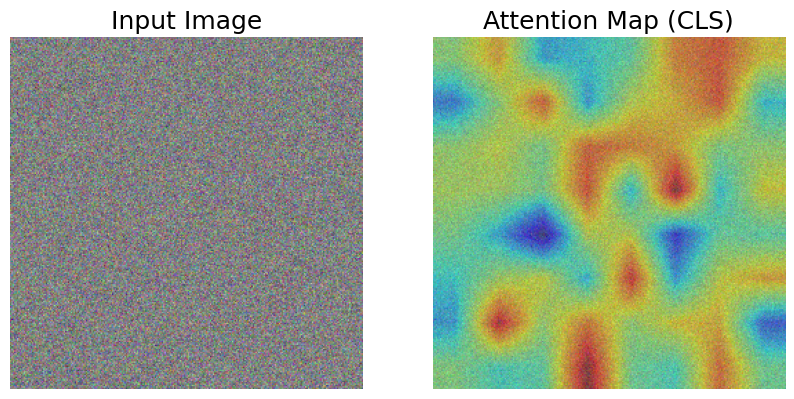

In [9]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# Forward pass
preds, attn = model_recorder(img)

# Choose last layer attention
attn_last = attn[-1]                     # (1, heads, 65, 65)

# Average heads
attn_mean = attn_last.mean(dim=1)        # (1, 65, 65)

# CLS token attention to patches
cls_attn = attn_mean[0, 0, 1:]           # (64,)

# Reshape to patch grid
patch_attn = cls_attn.reshape(8, 8)

# Upsample to image size
patch_attn = patch_attn.unsqueeze(0).unsqueeze(0)   # (1,1,8,8)
patch_attn = F.interpolate(patch_attn, size=256, mode='bilinear', align_corners=False)
patch_attn = patch_attn[0,0].detach().cpu().numpy()

# Normalize attention
patch_attn = patch_attn / patch_attn.max()

# Convert image to numpy
img_np = img[0].permute(1,2,0).detach().cpu().numpy()
img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min())

# Plot
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.title("Input Image")
plt.imshow(img_np)
plt.axis('off')

plt.subplot(1,2,2)
plt.title("Attention Map (CLS)")
plt.imshow(img_np)
plt.imshow(patch_attn, cmap='jet', alpha=0.5)
plt.axis('off')

plt.show()